# Практическая работа №1: Pandas — Датасет Titanic
Анализ данных пассажиров Титаника с использованием библиотеки Pandas (Задания 1–15).

### Задание 1. Загрузка и первичный просмотр данных

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("outputs", exist_ok=True)

# 1a. Загрузка датасета
df = pd.read_csv("Titanic.csv")

# 1b. Первые 5 строк
print("--- Первые 5 строк датасета ---")
print(df.head())

# 1c. Размер и общая информация
print(f"\nРазмер датасета (строк, столбцов): {df.shape}")
print("\n--- Информация о типах данных ---")
df.info()

# 1d. Уникальные значения пола
print("\nУникальные значения в столбце Sex:", df['Sex'].unique())

# 1e. Описательная статистика
print("\n--- Описательная статистика ---")
print(df.describe())

--- Первые 5 строк датасета ---
   PassengerId  Survived  Pclass  ...     Fare Cabin  Embarked
0            1         0       3  ...   7.2500   NaN         S
1            2         1       1  ...  71.2833   C85         C
2            3         1       3  ...   7.9250   NaN         S
3            4         1       1  ...  53.1000  C123         S
4            5         0       3  ...   8.0500   NaN         S

[5 rows x 12 columns]

Размер датасета (строк, столбцов): (891, 12)

--- Информация о типах данных ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch    

### Задание 2. Фильтрация данных

In [ ]:
# 2a. Только выжившие
survived_df = df[df['Survived'] == 1]

# 2b. Выбор колонок Name, Age, Sex
selected_cols = survived_df[['Name', 'Age', 'Sex']]
print("Выжившие пассажиры (первые 3 строки):\n", selected_cols.head(3))

# 2c. Средний возраст выживших по полу
avg_age_sex = survived_df.groupby('Sex')['Age'].mean()
print("\nСредний возраст выживших по полу:\n", avg_age_sex)

# 2d. Фильтрация по возрасту > 50
survived_over_50 = survived_df[survived_df['Age'] > 50]
print(f"\nКоличество выживших старше 50 лет: {len(survived_over_50)}")

# 2e. Сохранение результата в отдельный DataFrame
df_filtered_result = survived_over_50.copy()
print("Первые строки отфильтрованного DataFrame:\n", df_filtered_result[['Name', 'Age', 'Sex', 'Pclass']].head(3))

Выжившие пассажиры (первые 3 строки):
                                                 Name   Age     Sex
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0  female
2                             Heikkinen, Miss. Laina  26.0  female
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0  female

Средний возраст выживших по полу:
 Sex
female    28.847716
male      27.276022
Name: Age, dtype: float64

Количество выживших старше 50 лет: 22
Первые строки отфильтрованного DataFrame:
                                  Name   Age     Sex  Pclass
11           Bonnell, Miss. Elizabeth  58.0  female       1
15   Hewlett, Mrs. (Mary D Kingcome)   55.0  female       2
195              Lurette, Miss. Elise  58.0  female       1


### Задание 3. Работа с пропущенными значениями

In [ ]:
# 3a. Количество пропусков по колонкам
print("Пропуски до обработки:\n", df.isnull().sum())

# 3b. Заполнение Age медианой
df_clean = df.copy()
age_median = df_clean['Age'].median()
df_clean['Age'] = df_clean['Age'].fillna(age_median)
print(f"\nМедиана возраста для заполнения: {age_median}")

# 3c. Удаление строк с пропусками в Cabin и Embarked
df_dropped = df_clean.dropna(subset=['Cabin', 'Embarked'])
print(f"Размер после удаления пропусков в Cabin и Embarked: {df_dropped.shape}")

# 3d. Проверка оставшихся пропусков
print("\nПропуски в df_dropped:\n", df_dropped.isnull().sum())

# 3e. Создание полной копии DataFrame без каких-либо пропусков
df_no_nulls = df.dropna().copy()
print(f"Размер датасета без единого пропуска: {df_no_nulls.shape}")

Пропуски до обработки:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Медиана возраста для заполнения: 28.0
Размер после удаления пропусков в Cabin и Embarked: (202, 12)

Пропуски в df_dropped:
 PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64
Размер датасета без единого пропуска: (183, 12)


### Задание 4. Создание новых столбцов

In [ ]:
df_feat = df.copy()

# 4a. Извлечение титула (Title) из имени
df_feat['Title'] = df_feat['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
print("Топ-5 распространенных титулов:\n", df_feat['Title'].value_counts().head(5))

# 4b. Размер семьи FamilySize = SibSp + Parch
df_feat['FamilySize'] = df_feat['SibSp'] + df_feat['Parch']

# 4c. Доля выживших среди мужчин и женщин отдельно
survival_by_sex = df_feat.groupby('Sex')['Survived'].mean()
print("\nДоля выживших по полу:\n", survival_by_sex)

# 4d. Переименование столбцов
df_feat = df_feat.rename(columns={'Sex': 'Gender', 'Pclass': 'TicketClass'})

# 4e. Экспорт в CSV
df_feat.to_csv("outputs/titanic_modified.csv", index=False)
print("\nDataFrame с новыми столбцами сохранен в outputs/titanic_modified.csv")

Топ-5 распространенных титулов:
 Title
Mr        517
Miss      182
Mrs       125
Master     40
Dr          7
Name: count, dtype: int64

Доля выживших по полу:
 Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

DataFrame с новыми столбцами сохранен в outputs/titanic_modified.csv


### Задание 5. Агрегация данных и визуализация

Погибло (0): 549, Выжило (1): 342

Средний возраст по классам билетов:
 Pclass
1    38.233441
2    29.877630
3    25.140620
Name: Age, dtype: float64


<string>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


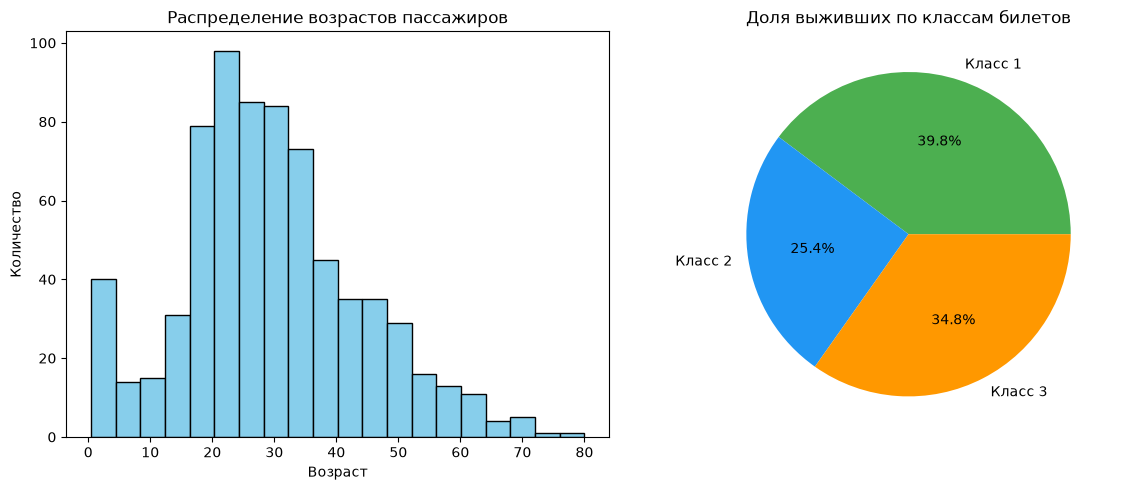

In [ ]:
# 5a. Количество погибших и выживших
counts = df['Survived'].value_counts()
print(f"Погибло (0): {counts.get(0, 0)}, Выжило (1): {counts.get(1, 0)}")

# 5b. Средний возраст по классу билета
avg_age_pclass = df.groupby('Pclass')['Age'].mean()
print("\nСредний возраст по классам билетов:\n", avg_age_pclass)

# 5c & 5d. Графики
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 5c. Гистограмма возрастов
axes[0].hist(df['Age'].dropna(), bins=20, color='skyblue', edgecolor='black')
axes[0].set_title('Распределение возрастов пассажиров')
axes[0].set_xlabel('Возраст')
axes[0].set_ylabel('Количество')

# 5d. Круговая диаграмма доли выживших по классам
surv_class = df[df['Survived'] == 1]['Pclass'].value_counts().sort_index()
axes[1].pie(surv_class, labels=[f'Класс {c}' for c in surv_class.index], autopct='%1.1f%%', colors=['#4CAF50', '#2196F3', '#FF9800'])
axes[1].set_title('Доля выживших по классам билетов')

plt.tight_layout()
# 5e. Сохранение в PNG
plt.savefig("outputs/titanic_aggregation.png", dpi=150)
plt.show()

### Задание 6. Сортировка данных

In [ ]:
# 6a. Сортировка по возрасту по убыванию
sorted_by_age = df.sort_values(by='Age', ascending=False)
print("Топ-3 старейших пассажира:\n", sorted_by_age[['Name', 'Age']].head(3))

# 6b. Пассажиры старше 60, сортировка по стоимости билета
seniors_fare = df[df['Age'] > 60].sort_values(by='Fare')
print("\nПассажиры старше 60 (сортировка по тарифу, первые 3):\n", seniors_fare[['Name', 'Age', 'Fare']].head(3))

# 6c. Пассажиры старше 18 лет в каждом классе
adults_by_class = df[df['Age'] > 18]['Pclass'].value_counts().sort_index()
print("\nКоличество пассажиров старше 18 лет по классам:\n", adults_by_class)

# 6d. Экспорт в Excel
sorted_by_age.head(100).to_excel("outputs/titanic_sorted.xlsx", index=False)
print("\nФайл сохранен в outputs/titanic_sorted.xlsx")

# 6e. Сводная таблица по количеству выживших и погибших
pivot_surv = pd.pivot_table(df, index='Pclass', columns='Survived', values='PassengerId', aggfunc='count')
pivot_surv.columns = ['Погибшие', 'Выжившие']
print("\nСводная таблица по классам и выживаемости:\n", pivot_surv)

Топ-3 старейших пассажира:
                                      Name   Age
630  Barkworth, Mr. Algernon Henry Wilson  80.0
851                   Svensson, Mr. Johan  74.0
493               Artagaveytia, Mr. Ramon  71.0

Пассажиры старше 60 (сортировка по тарифу, первые 3):
                           Name   Age    Fare
326  Nysveen, Mr. Johan Hansen  61.0  6.2375
116       Connors, Mr. Patrick  70.5  7.7500
280           Duane, Mr. Frank  65.0  7.7500

Количество пассажиров старше 18 лет по классам:
 Pclass
1    170
2    144
3    261
Name: count, dtype: int64

Файл сохранен в outputs/titanic_sorted.xlsx

Сводная таблица по классам и выживаемости:
         Погибшие  Выжившие
Pclass                    
1             80       136
2             97        87
3            372       119


### Задание 7. Применение функций к данным

In [ ]:
df_func = df.copy()

# 7a. Округление возраста
df_func['Age_Rounded'] = df_func['Age'].round()

# 7b. Кодирование пола в числовые / обратно в категориальные
df_func['Sex_Cat'] = df_func['Sex'].astype('category')

# 7c. Проверка и удаление дубликатов
duplicates_count = df_func.duplicated().sum()
print(f"Количество строк-дубликатов: {duplicates_count}")
df_func = df_func.drop_duplicates()

# 7d. Перевод имен в нижний регистр
df_func['Name_Lower'] = df_func['Name'].str.lower()

# 7e. Разделение и объединение имени
# Имена в датасете имеют вид: Lastname, Title. Firstname
df_func['Last_Name'] = df_func['Name'].apply(lambda x: x.split(',')[0].strip())
df_func['First_Name'] = df_func['Name'].apply(lambda x: x.split(',')[1].strip() if ',' in x else '')
df_func['Full_Name'] = df_func['First_Name'] + " " + df_func['Last_Name']

print("Пример объединенных имен Full_Name:\n", df_func[['Name', 'Full_Name']].head(3))

Количество строк-дубликатов: 0
Пример объединенных имен Full_Name:
                                                 Name                                          Full_Name
0                            Braund, Mr. Owen Harris                             Mr. Owen Harris Braund
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  Mrs. John Bradley (Florence Briggs Thayer) Cum...
2                             Heikkinen, Miss. Laina                              Miss. Laina Heikkinen


### Задание 8. Обработка строковых данных

In [ ]:
df_str = df.copy()

# 8a. Имена заглавными буквами
df_str['Name_Upper'] = df_str['Name'].str.upper()

# 8b. Удаление лишних пробелов в Embarked
df_str['Embarked'] = df_str['Embarked'].astype(str).str.strip()

# 8c. Замена пустых Cabin на Unknown
df_str['Cabin'] = df_str['Cabin'].fillna("Unknown")

# 8d. Самое длинное и короткое имя
longest_name = df_str.loc[df_str['Name'].str.len().idxmax()]['Name']
shortest_name = df_str.loc[df_str['Name'].str.len().idxmin()]['Name']
print(f"Самое длинное имя ({len(longest_name)} символов): {longest_name}")
print(f"Самое короткое имя ({len(shortest_name)} символов): {shortest_name}")

# 8e. Разделение имени на Title, First Name, Last Name
extracted = df_str['Name'].str.extract(r'^(?P<Last_Name>[^,]+),\s*(?P<Title>[^.]+)\.\s*(?P<First_Name>.*)$')
df_str = pd.concat([df_str, extracted], axis=1)
print("\nРезультат разделения имени (первые 3 строки):")
print(df_str[['Title', 'First_Name', 'Last_Name']].head(3))

Самое длинное имя (82 символов): Penasco y Castellana, Mrs. Victor de Satode (Maria Josefa Perez de Soto y Vallejo)
Самое короткое имя (12 символов): Lam, Mr. Ali

Результат разделения имени (первые 3 строки):
  Title                             First_Name  Last_Name
0    Mr                            Owen Harris     Braund
1   Mrs  John Bradley (Florence Briggs Thayer)    Cumings
2  Miss                                  Laina  Heikkinen


### Задание 9. Группировка данных

Количество пассажиров по полу и классу:
 Pclass    1    2    3
Sex                  
female   94   76  144
male    122  108  347

Процент выживших по возрастным группам (%):
 AgeGroup
(0, 10]      59.4
(10, 20]     38.3
(20, 30]     36.5
(30, 40]     44.5
(40, 50]     38.4
(50, 60]     40.5
(60, 70]     23.5
(70, 100]    20.0
Name: Survived, dtype: float64

Сводная таблица:
         Погибло  Выжило
Pclass                 
1            80     136
2            97      87
3           372     119

Вывод: Шансы на выживание напрямую зависели от класса каюты: в 1-м классе выживаемость превысила 60%, тогда как в 3-м классе составила менее 25%.


<string>:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


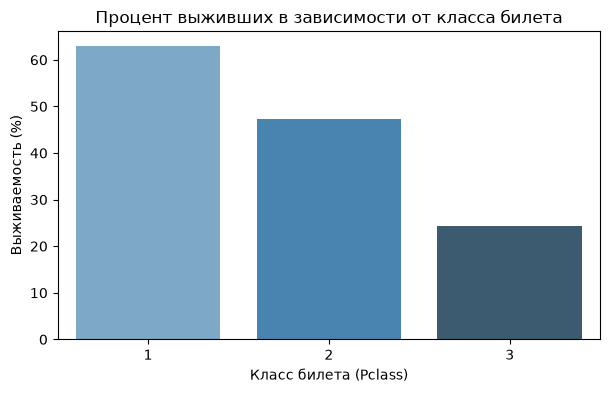

In [ ]:
# 9a. Группировка по полу и классу
group_sex_class = df.groupby(['Sex', 'Pclass']).size().unstack()
print("Количество пассажиров по полу и классу:\n", group_sex_class)

# 9b. Процент выживших по возрастным категориям
bins = [0, 10, 20, 30, 40, 50, 60, 70, 100]
df['AgeGroup'] = pd.cut(df['Age'], bins=bins)
survival_by_age = df.groupby('AgeGroup', observed=False)['Survived'].mean() * 100
print("\nПроцент выживших по возрастным группам (%):\n", survival_by_age.round(1))

# 9c. График зависимости выживаемости от класса
plt.figure(figsize=(7, 4))
pclass_surv = df.groupby('Pclass')['Survived'].mean() * 100
sns.barplot(x=pclass_surv.index, y=pclass_surv.values, palette='Blues_d')
plt.title('Процент выживших в зависимости от класса билета')
plt.xlabel('Класс билета (Pclass)')
plt.ylabel('Выживаемость (%)')
plt.show()

# 9d. Сводная таблица по классам
pivot_summary = pd.pivot_table(df, index='Pclass', columns='Survived', values='PassengerId', aggfunc='count')
pivot_summary.columns = ['Погибло', 'Выжило']
print("\nСводная таблица:\n", pivot_summary)

# 9e. Вывод
print("\nВывод: Шансы на выживание напрямую зависели от класса каюты: в 1-м классе выживаемость превысила 60%, тогда как в 3-м классе составила менее 25%.")

### Задание 10. Объединение и слияние данных

In [ ]:
# Подготовим две части датасета
df1 = df[['PassengerId', 'Name', 'Age']].copy()
df2 = df[['PassengerId', 'Pclass', 'Survived', 'Fare']].copy()

# 10a. Объединение по PassengerId
merged_inner = pd.merge(df1, df2, on='PassengerId')
print("Форма объединенного DataFrame:", merged_inner.shape)

# 10b. Левое объединение по полю Name
df_extra_info = df[['Name', 'Sex', 'Age']].rename(columns={'Age': 'Age_Ref'})
merged_left = pd.merge(df1, df_extra_info, on='Name', how='left')

# 10c. Разница между возрастами
merged_left['Age_Difference'] = merged_left['Age'] - merged_left['Age_Ref']

# 10d. Проверка уникальности
print(f"Все ли значения PassengerId уникальны?: {merged_inner['PassengerId'].is_unique}")

# 10e. Сохранение в JSON
merged_inner.head(50).to_json("outputs/titanic_merged.json", orient='records', indent=4)
print("Объединенный DataFrame сохранен в outputs/titanic_merged.json")

Форма объединенного DataFrame: (891, 6)
Все ли значения PassengerId уникальны?: True
Объединенный DataFrame сохранен в outputs/titanic_merged.json


### Задание 11. График распределения по возрасту

Вывод: Среди детей в возрасте до 10 лет доля выживших существенно выше, чем среди взрослых групп.


<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


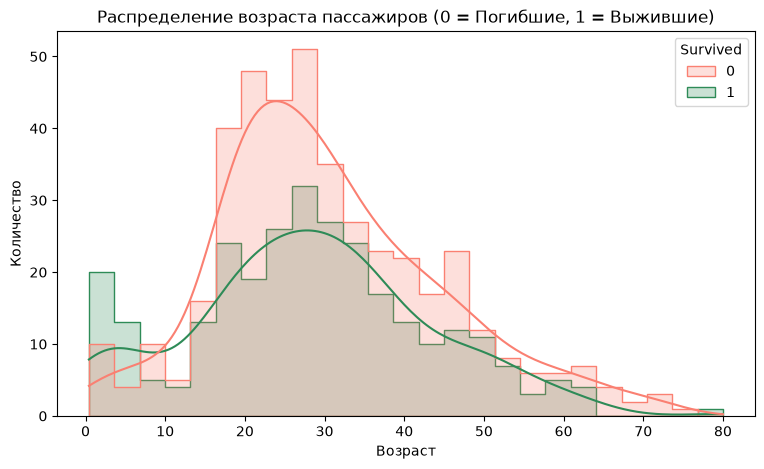

In [ ]:
plt.figure(figsize=(9, 5))

# 11a & 11c. Распределение выживших и погибших по возрасту
sns.histplot(data=df, x='Age', hue='Survived', kde=True, bins=25, palette={0: 'salmon', 1: 'seagreen'}, element='step')
plt.title('Распределение возраста пассажиров (0 = Погибшие, 1 = Выжившие)')
plt.xlabel('Возраст')
plt.ylabel('Количество')

# 11d. Сохранение в PDF
plt.savefig("outputs/titanic_age_dist.pdf")
plt.show()

# 11e. Объяснение
print("Вывод: Среди детей в возрасте до 10 лет доля выживших существенно выше, чем среди взрослых групп.")

### Задание 12. Анализ зависимостей стоимости билета от возраста

Закономерность: Тарифы первого класса существенно выше и имеют наибольший разброс цен, при этом для пассажиров пожилого возраста наблюдается большая концентрация в первом классе.


<string>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


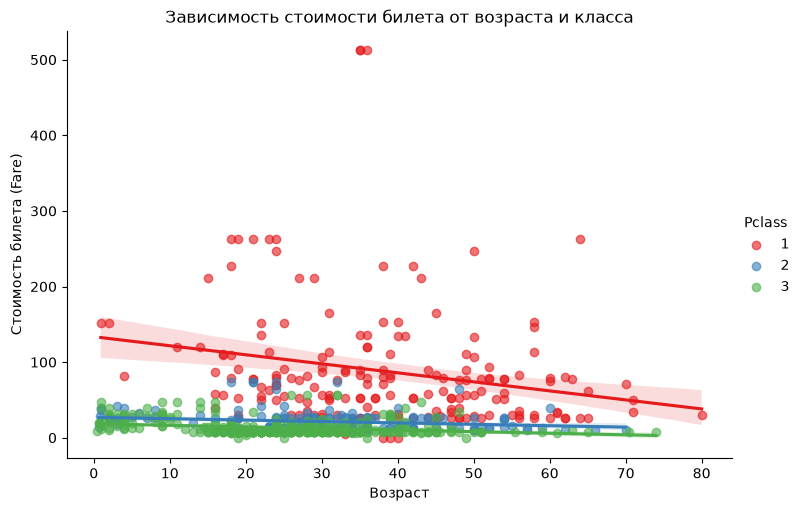

In [ ]:
g = sns.lmplot(data=df, x='Age', y='Fare', hue='Pclass', palette='Set1', aspect=1.5, height=5, scatter_kws={'alpha': 0.6})
g.set_axis_labels('Возраст', 'Стоимость билета (Fare)')
plt.title('Зависимость стоимости билета от возраста и класса')

# 12d. Сохранение в SVG
g.savefig("outputs/titanic_scatter.svg")
plt.show()

# 12e. Описание закономерности
print("Закономерность: Тарифы первого класса существенно выше и имеют наибольший разброс цен, при этом для пассажиров пожилого возраста наблюдается большая концентрация в первом классе.")

### Задание 13. Анализ влияния различных факторов на выживаемость

Выводы: Женщины во всех классах имели значительно больший шанс спастись (в 1 и 2 классах свыше 85-95%). Мужчины третьего класса имели самый низкий показатель выживаемости (~13%).


<string>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


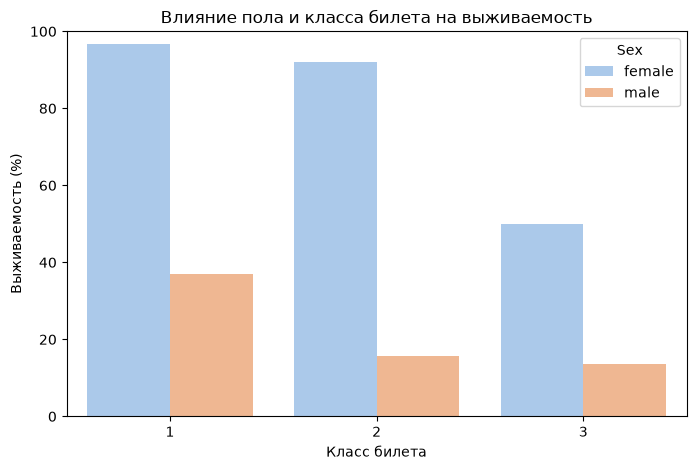

In [ ]:
# 13a & 13b. Группы по полу и классу с расчетом процента выживших
factor_rates = df.groupby(['Sex', 'Pclass'])['Survived'].mean().reset_index()
factor_rates['Survival_Rate'] = factor_rates['Survived'] * 100

# 13c. Столбчатая диаграмма
plt.figure(figsize=(8, 5))
sns.barplot(data=factor_rates, x='Pclass', y='Survival_Rate', hue='Sex', palette='pastel')
plt.title('Влияние пола и класса билета на выживаемость')
plt.ylabel('Выживаемость (%)')
plt.xlabel('Класс билета')
plt.ylim(0, 100)
plt.show()

# 13d. Выводы
print("Выводы: Женщины во всех классах имели значительно больший шанс спастись (в 1 и 2 классах свыше 85-95%). Мужчины третьего класса имели самый низкий показатель выживаемости (~13%).")

### Задание 14. Разведывательный анализ данных (EDA)

Описательные статистики ключевых числовых признаков:
               Age        Fare       SibSp       Parch
count  714.000000  891.000000  891.000000  891.000000
mean    29.699118   32.204208    0.523008    0.381594
std     14.526497   49.693429    1.102743    0.806057
min      0.420000    0.000000    0.000000    0.000000
25%     20.125000    7.910400    0.000000    0.000000
50%     28.000000   14.454200    0.000000    0.000000
75%     38.000000   31.000000    1.000000    0.000000
max     80.000000  512.329200    8.000000    6.000000
Признак 'Fare': найдено выбросов 116 из 891
Признак 'Age': найдено выбросов 11 из 714

Вывод: Признак Fare имеет сильную асимметрию вправо с выраженными выбросами (сверхдорогие билеты). Признак Age распределен близко к нормальному со смещением в сторону молодых людей.


<string>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


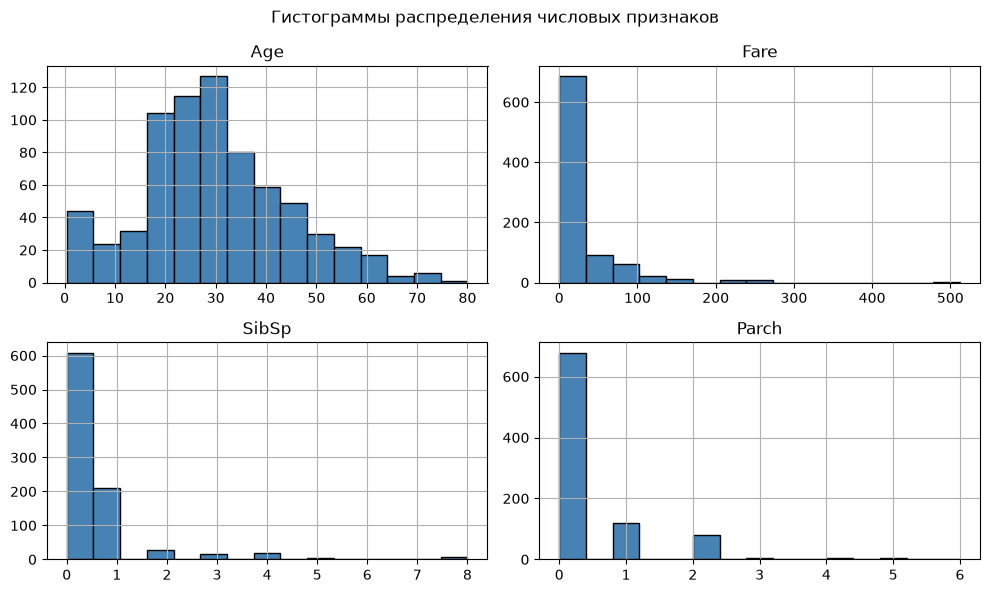

In [ ]:
# 14a. Ключевые показатели
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']
print("Описательные статистики ключевых числовых признаков:\n", df[num_cols].describe())

# 14b. Гистограммы признаков
df[num_cols].hist(figsize=(10, 6), bins=15, color='steelblue', edgecolor='black')
plt.suptitle('Гистограммы распределения числовых признаков')
plt.tight_layout()
plt.show()

# 14c. Поиск выбросов (Outliers) методом IQR
for col in ['Fare', 'Age']:
    valid = df[col].dropna()
    q25, q75 = np.percentile(valid, [25, 75])
    iqr = q75 - q25
    outliers = valid[(valid < q25 - 1.5 * iqr) | (valid > q75 + 1.5 * iqr)]
    print(f"Признак '{col}': найдено выбросов {len(outliers)} из {len(valid)}")

# 14d. Выводы
print("\nВывод: Признак Fare имеет сильную асимметрию вправо с выраженными выбросами (сверхдорогие билеты). Признак Age распределен близко к нормальному со смещением в сторону молодых людей.")

### Задание 15. Базовая предобработка данных

In [ ]:
df_prep = pd.read_csv("Titanic.csv")

# 15a. Пропущенные значения
print("Пропуски до обработки:\n", df_prep.isnull().sum())

# 15b. Заполнение возраста медианой
df_prep['Age'] = df_prep['Age'].fillna(df_prep['Age'].median())

# 15c. Преобразование пола в числовой (male -> 0, female -> 1)
df_prep['Sex'] = df_prep['Sex'].map({'male': 0, 'female': 1})

# 15d. Удаление столбцов с большим количеством пропусков или неинформативных
cols_to_drop = ['Cabin', 'Ticket', 'PassengerId', 'Name']
df_prep = df_prep.drop(columns=[c for c in cols_to_drop if c in df_prep.columns])

# Заполняем оставшиеся 2 пропуска в Embarked модой
df_prep['Embarked'] = df_prep['Embarked'].fillna(df_prep['Embarked'].mode()[0])

# 15e. Сохранение обработанных данных в CSV
df_prep.to_csv("outputs/titanic_preprocessed.csv", index=False)
print("\nРазмер предобработанного набора данных:", df_prep.shape)
print("Итоговые пропуски:\n", df_prep.isnull().sum())
print("Предобработанный датасет сохранен в outputs/titanic_preprocessed.csv")

Пропуски до обработки:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Размер предобработанного набора данных: (891, 8)
Итоговые пропуски:
 Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64
Предобработанный датасет сохранен в outputs/titanic_preprocessed.csv
